# Module 1: running a crop model, phenology, sensitivity and potential production

This notebook follows the first day of a DSSAT training course: run an existing experiment, look at
how the crop model times development, change one input at a time, and build a "potential production"
experiment in which only weather, CO2 and the cultivar limit the crop.

Everything the DSSAT shell does through windows (XBuild, the Sensitivity Analysis tool, GBuild) is done
here in Python, with xdssat's modules (`src/filex.py`, `src/runner.py`, `src/genotype.py`), and the
stock DSSAT engine `dscsm048` (DSSAT-CSM 4.8).

**Data.** The maize experiment UFGA8201 (Gainesville, Florida, 1982; McCurdy 84aa; three water x two
nitrogen treatments) and its weather and soil come from
[DSSAT/dssat-csm-data](https://github.com/DSSAT/dssat-csm-data) (BSD-3), pinned to one commit below.

**Needs.** The DSSAT engine (`XDSSAT_ENGINE`), a short work folder outside OneDrive (`XDSSAT_WORK`), and
`dssat-csm-data` cloned next to this repository. See `docs/getting-started.md`. The cells write only to
the work folder and, at the end of each part, small CSV files in `docs/learn/data/module1/` that the
website reads.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))      # docs/notebooks, where this notebook lives
import learnlib as L
from wth import read_wth

M = "module1"
print("engine      :", L.config.engine_exe())
print("work root   :", L.config.WORK_ROOT)
print("csm-data    :", L.CSM_DATA, "@", L.CSM_DATA_COMMIT[:8])
print("experiment  :", L.csm_data_url("Maize/UFGA8201.MZX"))

engine      : C:\TEMP\dsn\dssat\dscsm048.exe
work root   : C:\TEMP\dsn\work
csm-data    : C:\Users\benny\OneDrive\Documents\Github\dssat-csm-data @ 99c95b34
experiment  : https://github.com/DSSAT/dssat-csm-data/blob/99c95b340acb9515c2d0a8ab582f5fbbf076f345/Maize/UFGA8201.MZX


## 0. What is inside DSSAT's Cropping System Model

DSSAT's Cropping System Model (CSM) is one Fortran program built from modules: one for the weather, one for
the soil (water, nitrogen, carbon, temperature), one for the soil-plant-atmosphere exchange (`SPAM`), one for
management, and a family of plant models plugged into the same interface [@jones2003]. Counting the source
code of the engine used here (dssat-csm-os at the pinned commit) shows how the work is divided:

In [2]:
OSDIR = L.ROOT.parent / "dssat-csm-os"
rows = []
for d in ["Plant", "Soil", "SPAM", "Weather", "Management", "InputModule", "Utilities", "CSM_Main"]:
    files = [f for f in (OSDIR / d).rglob("*") if f.suffix.lower() in (".for", ".f90")]
    rows.append({"module": d, "source_files": len(files), "lines": sum(len(f.read_text(encoding="latin-1", errors="replace").splitlines()) for f in files)})
csm = pd.DataFrame(rows)
plants = []
for sub in sorted(p for p in (OSDIR / "Plant").iterdir() if p.is_dir()):
    files = [f for f in sub.rglob("*") if f.suffix.lower() in (".for", ".f90")]
    plants.append({"plant_model": sub.name, "source_files": len(files)})
plants = pd.DataFrame(plants)
spe = (L.Path(L.config.ENGINE_DIR) / "Genotype" / "SBGRO048.SPE").read_text(encoding="latin-1").splitlines()
i = next(k for k, l in enumerate(spe) if l.startswith("!  TB   TO1   TO2    TM"))
tfun = pd.DataFrame([dict(zip(["TB", "TO1", "TO2", "TM"], map(float, spe[i + j].split()[:4])), phase=" ".join(spe[i + j].split()[5:])) for j in (1, 2, 3)])
L.export(csm, M, "csm_modules"); L.export(plants, M, "csm_plant_models"); L.export(tfun, M, "cropgro_temperature")
display(csm, tfun)
plants

,module,source_files,lines
0,Plant,361,214677
1,Soil,78,32636
2,SPAM,14,9092
3,Weather,9,5801
4,Management,13,6249
5,InputModule,40,20345
6,Utilities,21,22920
7,CSM_Main,2,1233


,TB,TO1,TO2,TM,phase
0,7.0,28.0,35.0,45.0,VEGETATIVE DEVELOPMENT
1,6.0,26.0,30.0,45.0,EARLY REPRODUCTIVE DEVELOPMENT
2,-15.0,26.0,34.0,45.0,LATE REPRODUCTIVE DEVELOPMENT


,plant_model,source_files
0,ALOHA-Pineapple,9
1,AROIDS,13
2,CANEGRO-Sugarcane,17
3,CASUPRO-Sugarcane,20
4,CERES-IXIM-Maize,9
5,CERES-Maize,10
6,CERES-Millet,10
7,CERES-Rice,15
8,CERES-SharedFiles,2
9,CERES-Sorghum,8


## 1. Running a crop model

A DSSAT experiment file (FileX, here `UFGA8201.MZX`) lists **factor levels** (cultivars, fields,
initial conditions, planting, irrigation, fertilizer, simulation controls ...) and **treatments**, each a
combination of one level per factor. The table below is the FileX's own treatment section.

In [3]:
fx = L.filex.FileX.read(L.CSM_DATA / "Maize/UFGA8201.MZX")
trt = fx.treatments().reset_index()
trt[["N", "TNAME", "CU", "FL", "IC", "MP", "MI", "MF", "SM"]] if "N" in trt else trt

,N,TNAME,CU,FL,IC,MP,MI,MF,SM
0,1,RAINFED LOW NITROGEN,1,1,1,1,1,1,1
1,2,RAINFED HIGH NITROGEN,1,1,1,1,1,2,1
2,3,IRRIGATED LOW NITROGEN,1,1,1,1,2,1,1
3,4,IRRIGATED HIGH NITROGEN,1,1,1,1,2,2,1
4,5,VEG STRESS LOW NITROGEN,1,1,1,1,3,1,1
5,6,VEG STRESS HIGH NITROGEN,1,1,1,1,3,2,1


In the DSSAT shell you would select the six treatments and press *Run*. Here: copy the experiment, its
observed data (FileA `.MZA`, FileT `.MZT`), the weather file and the soil file into a fresh work folder and
call the engine on it. `outputs="daily"` asks for the daily CSV outputs (PlantGro, SoilWat, Weather ...).

In [4]:
run1 = L.work_dir("m1_base")
L.stage(run1, "Maize/UFGA8201.MZX", "Maize/UFGA8201.MZA", "Maize/UFGA8201.MZT",
        "Weather/UFGA8201.WTH", "Soil/SOIL.SOL")
summ, daily, res = L.run(run1, "UFGA8201.MZX")
print(f"{len(summ)} treatments in {res.seconds:.1f} s, model {summ.MODEL.iloc[0]}")
summ[["TRNO", "TNAM", "PDAT", "ADAT", "MDAT", "HWAM", "CWAM", "LAIX", "PRCM", "IRCM", "NUCM"]]

6 treatments in 1.7 s, model MZCER048


,TRNO,TNAM,PDAT,ADAT,MDAT,HWAM,CWAM,LAIX,PRCM,IRCM,NUCM
0,1,RAINFED LOW NITROGEN,1982057,1982133,1982185,2293,6556,1.988984,661,13,98
1,2,RAINFED HIGH NITROGEN,1982057,1982133,1982185,2293,7538,3.273873,661,13,132
2,3,IRRIGATED LOW NITROGEN,1982057,1982133,1982185,8207,14578,2.507062,661,264,137
3,4,IRRIGATED HIGH NITROGEN,1982057,1982133,1982185,11854,22454,4.547936,661,264,249
4,5,VEG STRESS LOW NITROGEN,1982057,1982133,1982185,7718,13458,2.507062,661,201,132
5,6,VEG STRESS HIGH NITROGEN,1982057,1982133,1982185,10293,19234,4.030581,661,201,224


### Simulated against observed

The FileA holds what was measured at the end of the season. Dates become days after planting (DAP) so
they can be compared.

In [5]:
obsA = L.read_filea(run1 / "UFGA8201.MZA")
pdate = pd.Timestamp("1982-02-26")
def dap(v):
    return (pd.to_datetime(str(int(v)), format="%Y%j") - pdate).days if pd.notna(v) else np.nan

rows = []
for _, s in summ.iterrows():
    o = obsA[obsA.TRNO == s.TRNO].iloc[0]
    for var, sim, ob in [("Grain yield, kg/ha", s.HWAM, o.HWAM), ("Tops weight, kg/ha", s.CWAM, o.CWAM),
                         ("LAI, maximum", s.LAIX, o.LAIX),
                         ("Anthesis, DAP", dap(s.ADAT), (o.ADAT - pdate).days),
                         ("Maturity, DAP", dap(s.MDAT), (o.MDAT - pdate).days)]:
        rows.append({"TRNO": int(s.TRNO), "treatment": s.TNAM.strip().title(), "variable": var,
                     "simulated": float(sim), "observed": float(ob)})
final = pd.DataFrame(rows)
final["sim/obs"] = final.simulated / final.observed
final.pivot_table(index=["TRNO", "treatment"], columns="variable", values=["simulated", "observed"]).round(2)

observed                                  \
variable                      Anthesis, DAP Grain yield, kg/ha LAI, maximum   
TRNO treatment                                                                
1    Rainfed Low Nitrogen              75.0             2929.0         2.26   
2    Rainfed High Nitrogen             75.0             3130.0         2.84   
3    Irrigated Low Nitrogen            75.0             6850.0         3.26   
4    Irrigated High Nitrogen           75.0            11881.0         4.09   
5    Veg Stress Low Nitrogen           75.0             6375.0         2.76   
6    Veg Stress High Nitrogen          75.0             9344.0         3.70   

                                                                   simulated  \
variable                      Maturity, DAP Tops weight, kg/ha Anthesis, DAP   
TRNO treatment                                                                 
1    Rainfed Low Nitrogen             128.0             5532.0          76.0   
2    Rainfed High Nitrogen            128.0             7201.0          76.0   
3    Irrigated Low Nitrogen           128.0            14581.0          76.0   
4    Irrigated High Nitrogen          128.0            22001.0          76.0   
5    Veg Stress Low Nitrogen          128.0            12002.0          76.0   
6    Veg Stress High Nitrogen         128.0            17146.0          76.0   

                                                                             \
variable                      Grain yield, kg/ha LAI, maximum Maturity, DAP   
TRNO treatment                                                                
1    Rainfed Low Nitrogen                 2293.0         1.99         128.0   
2    Rainfed High Nitrogen                2293.0         3.27         128.0   
3    Irrigated Low Nitrogen               8207.0         2.51         128.0   
4    Irrigated High Nitrogen             11854.0         4.55         128.0   
5    Veg Stress Low Nitrogen              7718.0         2.51         128.0   
6    Veg Stress High Nitrogen            10293.0         4.03         128.0   

                                                  
variable                      Tops weight, kg/ha  
TRNO treatment                                    
1    Rainfed Low Nitrogen                 6556.0  
2    Rainfed High Nitrogen                7538.0  
3    Irrigated Low Nitrogen              14578.0  
4    Irrigated High Nitrogen             22454.0  
5    Veg Stress Low Nitrogen             13458.0  
6    Veg Stress High Nitrogen            19234.0

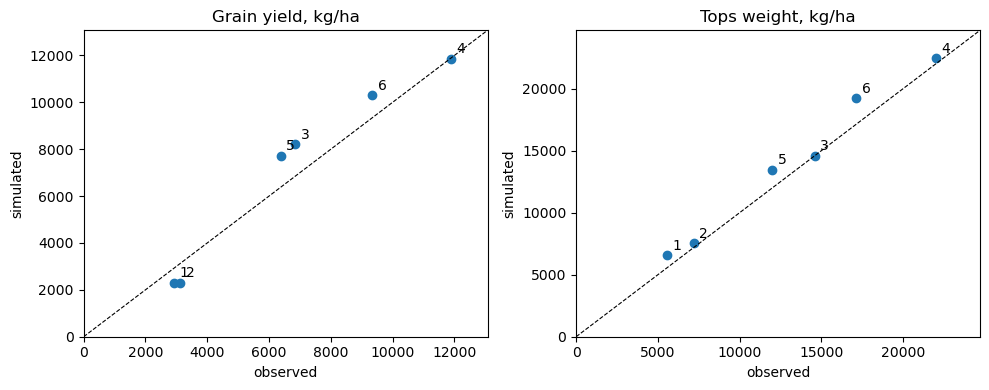

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, var in zip(axs, ["Grain yield, kg/ha", "Tops weight, kg/ha"]):
    d = final[final.variable == var]
    ax.scatter(d.observed, d.simulated)
    for _, r in d.iterrows():
        ax.annotate(str(r.TRNO), (r.observed, r.simulated), textcoords="offset points", xytext=(4, 4))
    lim = [0, max(d.observed.max(), d.simulated.max()) * 1.1]
    ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("observed"); ax.set_ylabel("simulated"); ax.set_title(var)
plt.tight_layout()

### Growth over the season

`PlantGro` holds the simulated crop every day; the FileT has the field samples. RMSE and Willmott's index
of agreement *d* (1 = perfect) summarise the fit per treatment, as the GBuild *Statistics* option does.

In [7]:
pg = daily["plantgro"]
gsim = pg[["TRNO", "date", "DAP", "GSTD", "LAID", "CWAD", "GWAD", "WSGD", "NSTD"]].copy()
obsT = L.read_filet(run1 / "UFGA8201.MZT")
gobs = obsT[["TRNO", "date", "LAID", "CWAD", "GWAD"]].copy()
gobs["DAP"] = (gobs.date - pdate).dt.days

stats = []
for (t, var), _ in gobs.melt(id_vars=["TRNO", "date", "DAP"]).groupby(["TRNO", "variable"]):
    o = gobs[gobs.TRNO == t][["date", var]].dropna()
    s = gsim[gsim.TRNO == t].set_index("date")[var]
    o = o[o.date.isin(s.index)]
    stats.append({"TRNO": t, "variable": var, "n": len(o), "rmse": L.rmse(o[var], s.loc[o.date]),
                  "d": L.willmott_d(o[var], s.loc[o.date])})
stats = pd.DataFrame(stats)
stats.pivot(index="TRNO", columns="variable", values=["rmse", "d"]).round(2)

rmse                   d            
variable     CWAD    GWAD  LAID  CWAD  GWAD  LAID
TRNO                                             
1         1321.06  189.93  0.67  0.91  0.98  0.64
2         1610.28  201.51  1.02  0.91  0.98  0.66
3         1776.26  771.74  1.06  0.97  0.97  0.69
4         2466.43  451.09  1.49  0.97  1.00  0.79
5         1576.58  532.66  0.97  0.97  0.99  0.69
6         2202.13  337.84  1.26  0.97  1.00  0.77

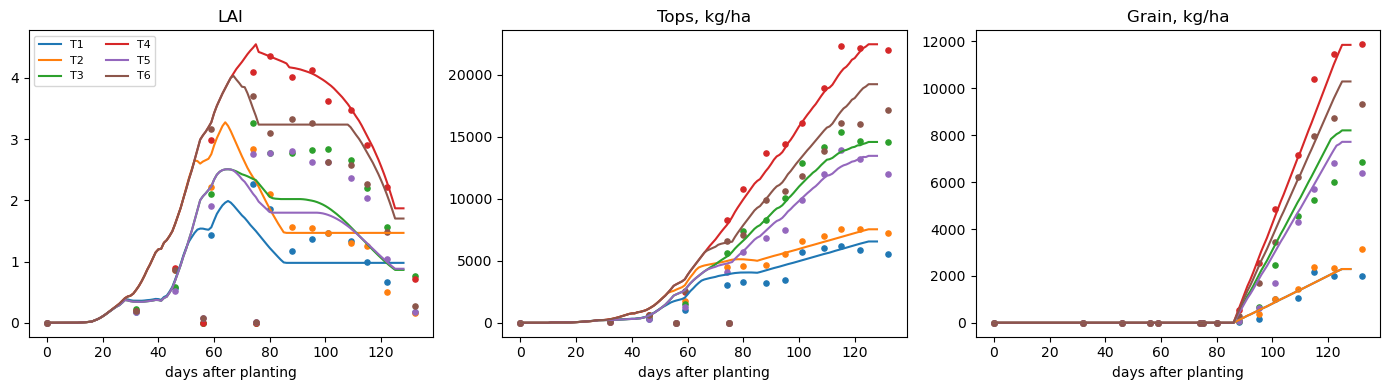

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, var, lab in zip(axs, ["LAID", "CWAD", "GWAD"], ["LAI", "Tops, kg/ha", "Grain, kg/ha"]):
    for t, g in gsim.groupby("TRNO"):
        line, = ax.plot(g.DAP, g[var], label=f"T{t}")
        o = gobs[gobs.TRNO == t]
        ax.scatter(o.DAP, o[var], color=line.get_color(), s=14)
    ax.set_xlabel("days after planting"); ax.set_title(lab)
axs[0].legend(ncol=2, fontsize=8)
plt.tight_layout()

In [9]:
tmeta = trt.rename(columns={"N": "TRNO"})[["TRNO", "TNAME"]].copy() if "N" in trt else trt
tmeta["water"] = ["rainfed", "rainfed", "irrigated", "irrigated", "vegetative stress", "vegetative stress"]
tmeta["nitrogen"] = ["low", "high"] * 3
L.export(tmeta, M, "treatments")
L.export(final, M, "final")
L.export(gsim, M, "growth_sim")
L.export(gobs, M, "growth_obs")
L.export(stats, M, "stats")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module1/stats.csv')

## 2. Phenology: thermal time

CERES-Maize counts development in **thermal time** (degree-days above a base temperature). Each phase
ends when its thermal-time requirement is met: P1 (emergence to end of the juvenile phase, a cultivar
coefficient), a photoperiod-sensitive induction phase (P2), then silking, grain filling (P5) and maturity.

The daily thermal time `DTT` is computed in
[`Plant/CERES-Maize/MZ_PHENOL.for`, lines 437-517](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Plant/CERES-Maize/MZ_PHENOL.for#L437):

- `TMAX < TBASE`: no development (`DTT = 0`);
- `TMIN > DOPT`: the maximum, `DOPT - TBASE`;
- while the crop has 10 leaves or fewer, the growing point is near the soil surface and a soil-temperature
  estimate replaces air temperature (not reproduced below);
- if `TMIN < TBASE` or `TMAX > DOPT`: 24 hourly temperatures from a sine curve, each clipped to
  `[TBASE, DOPT]`, averaged;
- otherwise the daily mean minus `TBASE`.

`TBASE`, `TOPT` (= `DOPT` before anthesis) and `ROPT` (after) are read from the ecotype file. The code
below reads them from the engine's own `MZCER048.ECO` and the cultivar's coefficients from `MZCER048.CUL`.

In [10]:
eco_path = Path(L.config.ENGINE_DIR) / "Genotype" / "MZCER048.ECO"
eco_lines = eco_path.read_text(encoding="latin-1").splitlines()
hdr = next(l for l in eco_lines if l.startswith("@ECO#")).split()
row = next(l for l in eco_lines if l.startswith("IB0001"))
eco = dict(zip(hdr[2:], row[24:].split()))        # skip ECO# and the 16-character name
eco = {k: float(v) for k, v in eco.items() if k in ("TBASE", "TOPT", "ROPT", "P20", "DJTI", "GDDE")}
cul = L.cultivar_table("MZCER048")
mccurdy = cul[cul["var"] == "IB0035"].iloc[0]
print("ecotype IB0001:", eco)
print("McCurdy 84aa  :", mccurdy[["P1", "P2", "P5", "G2", "G3", "PHINT"]].to_dict())

ecotype IB0001: {'TBASE': 8.0, 'TOPT': 34.0, 'ROPT': 34.0, 'P20': 12.5, 'DJTI': 4.0, 'GDDE': 6.0}
McCurdy 84aa  : {'P1': 259.0, 'P2': 1.193, 'P5': 947.1, 'G2': 924.3, 'G3': 8.168, 'PHINT': 43.0}


In [11]:
def dtt(tmax, tmin, tbase=8.0, dopt=34.0):
    # Air-temperature branches of MZ_PHENOL.for:445-513 (the soil-temperature branch for
    # LEAFNO <= 10 is left out on purpose).
    if tmax < tbase:
        return 0.0
    if tmin > dopt:
        return dopt - tbase
    if tmin < tbase or tmax > dopt:
        h = np.arange(1, 25)
        th = (tmax + tmin) / 2 + (tmax - tmin) / 2 * np.sin(3.14 / 12 * h)
        return float(np.mean(np.clip(th, tbase, dopt) - tbase))
    return (tmax + tmin) / 2 - tbase

hdr_w, w = read_wth(run1 / "UFGA8201.WTH")
w = w.rename(columns=str.upper).rename_axis("date").reset_index()
season = w[(w.date >= "1982-02-01") & (w.date <= "1982-09-30")].copy()
season["DTT_air"] = [dtt(a, b, eco["TBASE"], eco["TOPT"]) for a, b in zip(season.TMAX, season.TMIN)]
after = season.date >= pdate
season["GDD_cum"] = season.DTT_air.where(after, 0).cumsum()
season[["date", "TMAX", "TMIN", "DTT_air", "GDD_cum"]].iloc[20:30]

,date,TMAX,TMIN,DTT_air,GDD_cum
51,1982-02-21,24.4,9.4,8.900000,0.00000
52,1982-02-22,21.1,7.8,6.457897,0.00000
53,1982-02-23,23.9,1.1,6.174711,0.00000
54,1982-02-24,26.7,3.3,7.921077,0.00000
55,1982-02-25,27.2,10.6,10.900000,0.00000
56,1982-02-26,26.7,11.1,10.900000,10.90000
57,1982-02-27,25.6,8.9,9.250000,20.15000
58,1982-02-28,24.4,15.6,12.000000,32.15000
59,1982-03-01,17.8,8.3,5.050000,37.20000
60,1982-03-02,22.8,1.7,5.767770,42.96777


In [12]:
# Stage changes simulated by the engine for the irrigated high-N treatment (GSTD in PlantGro)
g4 = gsim[gsim.TRNO == 4].copy()
g4["stage"] = g4.GSTD.round().astype(int)
stages = g4.groupby("stage").agg(date=("date", "first"), DAP=("DAP", "first")).reset_index()
stages = stages.merge(season[["date", "GDD_cum"]], on="date", how="left")
stages

,stage,date,DAP,GDD_cum
0,0,1982-02-26,0,10.900000
1,1,1982-03-09,11,108.441091
2,2,1982-03-27,29,352.774424
3,3,1982-04-01,34,402.524424
4,4,1982-05-13,76,954.099323
5,5,1982-05-24,87,1133.449323


WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module1/coefficients.csv')

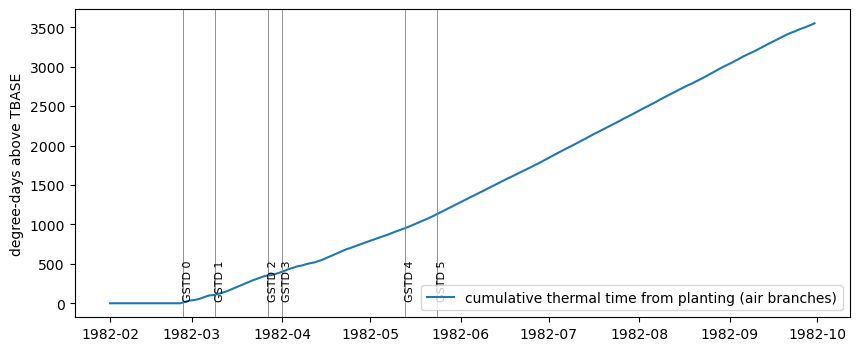

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(season.date, season.GDD_cum, label="cumulative thermal time from planting (air branches)")
for _, s in stages.iterrows():
    ax.axvline(s.date, color="grey", lw=0.6); ax.text(s.date, 50, f"GSTD {s.stage}", rotation=90, fontsize=8)
ax.set_ylabel("degree-days above TBASE"); ax.legend()
L.export(season[["date", "TMAX", "TMIN", "SRAD", "RAIN", "DTT_air", "GDD_cum"]], M, "weather")
L.export(stages, M, "stages")
L.export(pd.DataFrame([{**eco, **mccurdy[["P1", "P2", "P5", "G2", "G3", "PHINT"]].to_dict()}]), M, "coefficients")

## 3. Potential production

The simplest experiment a crop model can run: water and nitrogen are not simulated (switches `WATER` and
`NITRO` set to `N` in the simulation controls), so nothing but weather, CO2 and the cultivar limit growth.
In DSSAT's shell this is the "UFGA8211" file built in XBuild. Here it is built in code from treatment 4 of
UFGA8201 with `filex.build_filex`; the planting date, the cultivar and the field are the same. The
one-letter switches are written by `learnlib.set_switches` where the engine reads them: each is the last
character of a 6-character field
([`InputModule/IPSIM.for:1001`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/InputModule/IPSIM.for#L1001),
`FORMAT (I3,11X,9(5X,A1))`).

When the water balance is off, DSSAT does not compute soil water at all
([`SPAM/SPAM.for:269`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/SPAM/SPAM.for#L269)),
and with the N switch off, CERES-Maize has no N stress
([`MZ_GROSUB.for:2059`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Plant/CERES-Maize/MZ_GROSUB.for#L2059)).

Two CO2 options are compared: `M`, the measured Mauna Loa series (UFGA8201's own setting), and `D`, the
static default `CO2BAS` of 380 ppm in `StandardData/CO2048.WDA`
([`Weather/CO2VAL.for:5-7`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Weather/CO2VAL.for#L5)).

In [14]:
TEMPLATE_TRT = 4      # irrigated, high N: the template the potential runs copy
def potential_units(names, pdates, extra=None):
    u = pd.DataFrame({"cell": names, "name": names, "wsta": "UFGA", "soil_id": "IBMZ910014",
                      "pdate": pdates, "trno_template": TEMPLATE_TRT})
    for k, v in (extra or {}).items():
        u[k] = v
    return u

pot = []
for co2 in ["M", "D"]:
    d = L.work_dir(f"m1_pot_{co2}")
    L.stage(d, "Weather/UFGA8201.WTH", "Soil/SOIL.SOL")
    name, _ = L.write_built(d, fx, potential_units([f"Potential CO2 {co2}"], [pdate]), "UFGA8211", ".MZX",
                            title="Potential production", switches={"WATER": "N", "NITRO": "N", "CO2": co2})
    s, dd, r = L.run(d, name)
    s["scenario"] = f"Potential, CO2 {co2}"
    s["CO2_mean"] = dd["weather"].CO2D.mean()
    pot.append(s)
    if co2 == "M":
        pot_growth = dd["plantgro"][["date", "DAP", "LAID", "CWAD", "GWAD"]].assign(scenario="Potential")
pot = pd.concat(pot)
print((d / name).read_text().split("*SIMULATION CONTROLS")[1][:600])
pot[["scenario", "CO2_mean", "ADAT", "MDAT", "HWAM", "CWAM", "LAIX"]]


@N GENERAL     NYERS NREPS START SDATE RSEED SNAME.................... SMODEL
 1 GE              1     1     S 82056  2150 N X IRRIGATION, GAINESVI
@N OPTIONS     WATER NITRO SYMBI PHOSP POTAS DISES  CHEM  TILL   CO2
 1 OP              N     N     N     N     N     N     N     Y     D
@N METHODS     WTHER INCON LIGHT EVAPO INFIL PHOTO HYDRO NSWIT MESOM MESEV MESOL
 1 ME              M     M     E     R     S     R     R     1     G     R     2
@N MANAGEMENT  PLANT IRRIG FERTI RESID HARVS
 1 MA              R     R     R     N     M
@N OUTPUTS     FNAME OVVEW SUMRY FROPT GROUT CAOUT WAOUT NIOU


,scenario,CO2_mean,ADAT,MDAT,HWAM,CWAM,LAIX
0,"Potential, CO2 M",340.887305,1982133,1982185,11859,23174,4.562119
0,"Potential, CO2 D",380.000000,1982133,1982185,11983,23367,4.569410


In [15]:
cmp_rows = [{"scenario": r.scenario, "group": "potential", "HWAM": r.HWAM, "CWAM": r.CWAM, "LAIX": r.LAIX,
             "CO2_mean": r.CO2_mean} for _, r in pot.iterrows()]
for _, s in summ.iterrows():
    o = obsA[obsA.TRNO == s.TRNO].iloc[0]
    cmp_rows.append({"scenario": f"T{int(s.TRNO)} {s.TNAM.strip().title()}", "group": "UFGA8201 treatments",
                     "HWAM": s.HWAM, "CWAM": s.CWAM, "LAIX": s.LAIX, "HWAM_obs": o.HWAM})
potential = pd.DataFrame(cmp_rows)
potential["share_of_potential"] = potential.HWAM / pot[pot.scenario.str.endswith("M")].HWAM.iloc[0]
L.export(potential, M, "potential")
L.export(pot_growth, M, "potential_growth")
potential.round(2)

,scenario,group,HWAM,CWAM,LAIX,CO2_mean,HWAM_obs,share_of_potential
0,"Potential, CO2 M",potential,11859,23174,4.56,340.89,NaN,1.00
1,"Potential, CO2 D",potential,11983,23367,4.57,380.00,NaN,1.01
2,T1 Rainfed Low Nitrogen,UFGA8201 treatments,2293,6556,1.99,NaN,2929.0,0.19
3,T2 Rainfed High Nitrogen,UFGA8201 treatments,2293,7538,3.27,NaN,3130.0,0.19
4,T3 Irrigated Low Nitrogen,UFGA8201 treatments,8207,14578,2.51,NaN,6850.0,0.69
5,T4 Irrigated High Nitrogen,UFGA8201 treatments,11854,22454,4.55,NaN,11881.0,1.00
6,T5 Veg Stress Low Nitrogen,UFGA8201 treatments,7718,13458,2.51,NaN,6375.0,0.65
7,T6 Veg Stress High Nitrogen,UFGA8201 treatments,10293,19234,4.03,NaN,9344.0,0.87


## 4. Sensitivity analysis

The Sensitivity Analysis tool changes one input and reruns. Under potential production (so water and N do
not blur the picture) we change, one at a time:

1. the **cultivar**: six maize cultivars of the engine's `MZCER048.CUL`, from short to long juvenile phase
   (P1), as extra treatments with a different `INGENO`;
2. the **planting date**: 26 February plus 0 to 10 weeks in 2-week steps (every date of the template moves
   with planting);
3. a **genetic coefficient**: P1 and P5 of McCurdy 84aa, through a per-run copy of the cultivar file
   (`genotype.write_cultivar_files`), leaving the engine's own file untouched.

In [16]:
eco_col = [c for c in cul.columns if c.startswith("ECO")][0]
cands = cul[(cul[eco_col] == "IB0001") & cul.P1.notna() & cul.P5.notna()].copy()
targets = [110, 160, 200, 260, 310, 360]
picked = []
for t in targets:
    c = cands.loc[~cands["var"].isin(picked)].iloc[(cands.loc[~cands["var"].isin(picked)].P1 - t).abs().argsort()[:1]]
    picked.append(c["var"].iloc[0])
if "IB0035" not in picked:
    picked[3] = "IB0035"
cv = cands[cands["var"].isin(picked)].sort_values("P1")
cv[["var", "name", "P1", "P2", "P5", "G2", "G3", "PHINT"]]

,var,name,P1,P2,P5,G2,G3,PHINT
9,990003,SHORT SEASON,110.0,0.300,680.0,820.4,6.600,38.9
2,PC0001,2500-2600 GDD,160.0,0.750,780.0,750.0,8.500,49.0
8,990002,MEDIUM SEASON,200.0,0.300,800.0,700.0,8.500,38.9
45,IB0035,McCurdy 84aa,259.0,1.193,947.1,924.3,8.168,43.0
69,IB0059,H6,310.0,0.300,685.0,907.9,10.000,38.9
74,IB0064,H.OBREGON,360.0,0.800,685.0,907.9,10.150,38.9


In [17]:
def growth_cols(dd, units, key):
    g = dd["plantgro"][["TRNO", "DAP", "LAID", "GWAD", "CWAD"]].merge(units[["TRNO", key]], on="TRNO")
    return g.drop(columns="TRNO")

def dap_of(v, p):
    return (pd.to_datetime(str(int(v)), format="%Y%j") - p).days if pd.notna(v) else np.nan

# 4.1 cultivars
d = L.work_dir("m1_sens_cul")
L.stage(d, "Weather/UFGA8201.WTH", "Soil/SOIL.SOL")
u = potential_units(list(cv["var"]), [pdate] * len(cv), {"CU.INGENO": list(cv["var"]), "CU.CNAME": list(cv["name"])})
name, u = L.write_built(d, fx, u, "UFGA8212", ".MZX", title="Cultivar sensitivity",
                        switches={"WATER": "N", "NITRO": "N"})
s, dd, _ = L.run(d, name)
s = s.merge(u[["TRNO", "cell"]], on="TRNO").merge(cv.rename(columns={"var": "cell"}), on="cell")
s["anthesis_dap"] = [dap_of(v, pdate) for v in s.ADAT]
s["maturity_dap"] = [dap_of(v, pdate) for v in s.MDAT]
sens_cul = s[["cell", "name", "P1", "P2", "P5", "G2", "G3", "anthesis_dap", "maturity_dap", "HWAM", "CWAM", "LAIX"]].rename(columns={"cell": "var"})
cul_growth = growth_cols(dd, u.rename(columns={"cell": "var"}), "var")
sens_cul

,var,name,P1,P2,P5,G2,G3,anthesis_dap,maturity_dap,HWAM,CWAM,LAIX
0,990003,SHORT SEASON,110.0,0.300,680.0,820.4,6.600,58,101,5002,13052,2.667704
1,PC0001,2500-2600 GDD,160.0,0.750,780.0,750.0,8.500,68,113,7751,16710,2.715381
2,990002,MEDIUM SEASON,200.0,0.300,800.0,700.0,8.500,67,114,8676,19389,4.012970
3,IB0035,McCurdy 84aa,259.0,1.193,947.1,924.3,8.168,76,128,11859,23174,4.562119
4,IB0059,H6,310.0,0.300,685.0,907.9,10.000,84,121,8615,22679,5.676199
5,IB0064,H.OBREGON,360.0,0.800,685.0,907.9,10.150,87,124,8119,23035,5.881617


In [18]:
# 4.2 planting dates
dates = [pdate + pd.Timedelta(weeks=2 * i) for i in range(6)]
d = L.work_dir("m1_sens_pd")
L.stage(d, "Weather/UFGA8201.WTH", "Soil/SOIL.SOL")
u = potential_units([f"{p:%d %b}" for p in dates], dates)
name, u = L.write_built(d, fx, u, "UFGA8213", ".MZX", title="Planting date sensitivity",
                        switches={"WATER": "N", "NITRO": "N"})
s, dd, _ = L.run(d, name)
s = s.merge(u[["TRNO", "cell", "pdate"]], on="TRNO")
s["anthesis_dap"] = [dap_of(v, p) for v, p in zip(s.ADAT, s.pdate)]
s["maturity_dap"] = [dap_of(v, p) for v, p in zip(s.MDAT, s.pdate)]
wx = season.set_index("date")
s["season_tmean"] = [wx.loc[p:pd.to_datetime(str(int(m)), format="%Y%j"), ["TMAX", "TMIN"]].mean().mean() for p, m in zip(s.pdate, s.MDAT)]
s["season_srad"] = [wx.loc[p:pd.to_datetime(str(int(m)), format="%Y%j"), "SRAD"].mean() for p, m in zip(s.pdate, s.MDAT)]
sens_pd = s[["cell", "pdate", "anthesis_dap", "maturity_dap", "HWAM", "CWAM", "LAIX", "season_tmean", "season_srad"]].rename(columns={"cell": "planting"})
pd_growth = growth_cols(dd, u.rename(columns={"cell": "planting"}), "planting")
sens_pd

,planting,pdate,anthesis_dap,maturity_dap,HWAM,CWAM,LAIX,season_tmean,season_srad
0,26 Feb,1982-02-26,76,128,11859,23174,4.562119,22.724031,18.560465
1,12 Mar,1982-03-12,72,122,9254,20381,4.982561,23.662602,19.184553
2,26 Mar,1982-03-26,70,120,12321,22919,4.802684,24.148760,19.363636
3,09 Apr,1982-04-09,67,116,9958,21487,5.173677,25.103419,19.458120
4,23 Apr,1982-04-23,65,114,11640,23595,5.229832,25.772174,19.427826
5,07 May,1982-05-07,62,112,10217,22157,5.328450,26.480973,19.307080


In [19]:
# 4.3 one coefficient at a time: P1 and P5 of McCurdy 84aa (IB0035)
coef_rows, coef_growth = [], []
for coef, values in {"P1": range(150, 376, 25), "P5": range(700, 1101, 50)}.items():
    for v in values:
        d = L.work_dir(f"m1_{coef}_{v}")
        L.stage(d, "Weather/UFGA8201.WTH", "Soil/SOIL.SOL")
        name, u = L.write_built(d, fx, potential_units([f"{coef} {v}"], [pdate]), "UFGA8214", ".MZX",
                                title=f"{coef} sensitivity", switches={"WATER": "N", "NITRO": "N"})
        s, dd, _ = L.run(d, name, cultivar_overrides={"IB0035": {coef: v}}, crop="MZCER048")
        r = s.iloc[0]
        coef_rows.append({"coefficient": coef, "value": v, "anthesis_dap": dap_of(r.ADAT, pdate),
                          "maturity_dap": dap_of(r.MDAT, pdate), "HWAM": r.HWAM, "CWAM": r.CWAM, "LAIX": r.LAIX})
        g = dd["plantgro"][["DAP", "LAID", "GWAD", "CWAD"]].assign(coefficient=coef, value=v)
        coef_growth.append(g)
sens_coef = pd.DataFrame(coef_rows)
coef_growth = pd.concat(coef_growth)
sens_coef

,coefficient,value,anthesis_dap,maturity_dap,HWAM,CWAM,LAIX
0,P1,150,63,119,11557,20126,2.885616
1,P1,175,67,122,12477,22017,3.417914
2,P1,200,68,123,12633,22178,3.566045
3,P1,225,70,124,12848,22852,3.937589
4,P1,250,74,127,12578,23315,4.305885
5,P1,275,80,132,10929,23081,5.064129
6,P1,300,84,134,10488,23517,5.394757
7,P1,325,86,136,9335,22400,5.454202
8,P1,350,89,139,9705,23879,5.683367
9,P1,375,90,140,10064,24463,5.710293


WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module1/sens_coef_growth.csv')

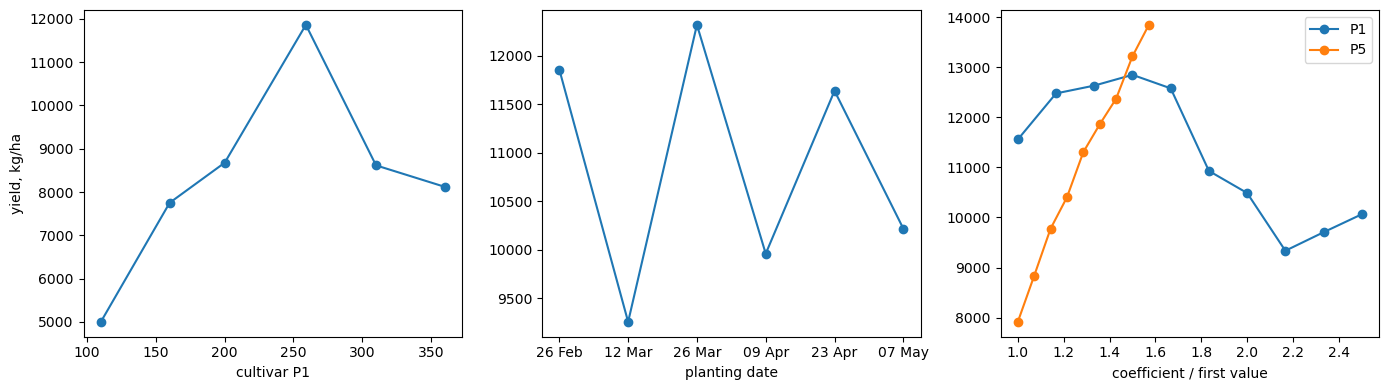

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(sens_cul.P1, sens_cul.HWAM, "o-"); axs[0].set_xlabel("cultivar P1"); axs[0].set_ylabel("yield, kg/ha")
axs[1].plot(range(len(sens_pd)), sens_pd.HWAM, "o-"); axs[1].set_xticks(range(len(sens_pd)), sens_pd.planting)
axs[1].set_xlabel("planting date")
for coef, g in sens_coef.groupby("coefficient"):
    axs[2].plot(g.value / g.value.iloc[0], g.HWAM, "o-", label=coef)
axs[2].set_xlabel("coefficient / first value"); axs[2].legend()
plt.tight_layout()
L.export(sens_cul, M, "sens_cultivar"); L.export(cul_growth, M, "sens_cultivar_growth")
L.export(sens_pd, M, "sens_pdate"); L.export(pd_growth, M, "sens_pdate_growth")
L.export(sens_coef, M, "sens_coef"); L.export(coef_growth, M, "sens_coef_growth")

## 5. What the numbers say, and things to try

The page that goes with this notebook (`learn/module1.qmd`) reads the CSV files written above and shows
them as interactive charts. Things to try in the notebook:

- Compare treatment 4 (irrigated, high N) with the potential run: how much of the potential did the field
  reach, and was water or nitrogen the larger limit (treatments 1-6)?
- Change `TEMPLATE_TRT`, or add a planting date in July: what happens to anthesis, maturity and yield, and
  why (see the season temperature and radiation columns)?
- Add G2 or G3 to the coefficient loop. Which coefficients move yield but not the dates?

In [21]:
info = pd.DataFrame([{"engine": str(L.config.engine_exe()), "model": summ.MODEL.iloc[0],
                      "csm_data_commit": L.CSM_DATA_COMMIT, "csm_os_commit": L.CSM_OS_COMMIT,
                      "run_on": time.strftime("%Y-%m-%d %H:%M")}])
L.export(info, M, "run_info")
info.T

,0
engine,C:\TEMP\dsn\dssat\dscsm048.exe
model,MZCER048
csm_data_commit,99c95b340acb9515c2d0a8ab582f5fbbf076f345
csm_os_commit,25c93b9a2f73f8ec45bf441b198dac5fb7b22849
run_on,2026-11-07 07:41
